# Extensional flows and the yield criterion

A rheometer calibrates the Herschel–Bulkley (HB) law in simple shear, but the law is used to predict flows that are not simple shear: a filament stretched under gravity, a paste squeezed between plates, a gel pulled apart in a cross-slot. Going from the measured flow curve to these flows requires a three-dimensional law, and that law contains two assumptions that the flow curve cannot fix: a **yield function** (which combination of stresses sets the onset of flow) and a **flow rule** (in which direction the material deforms once it yields). The tensorial HB law takes the von Mises yield function and an associated flow rule. Both are testable, and extensional flows are where they are tested: the law predicts that the tensile yield stress in uniaxial extension is $\sqrt3$ times the shear yield stress, whereas the alternative Tresca criterion predicts twice. This notebook builds the tensorial law in NumPy, verifies its simple-shear, uniaxial and planar limits, computes the difference between the two criteria over the Lode angle, confronts the predictions with the published extensional yield ratios, and ends with the question of whether the normal stresses of real yield-stress fluids move the yield invariant.

Notebook 02 (`02_flow_curves_and_dimensionless_groups.ipynb`, Sec. 4) introduces the tensorial law with a short `hb_tau` function and a first look at von Mises versus Tresca; notebook 10 treats normal stresses and the Saramito model in depth. Here we go further on the extensional side and refer to those notebooks rather than repeat them.

## Where this is in the review

* **Sec. IV A** *The tensorial law and the complete flow problem* — the three-dimensional HB law, **Eq. (4)**, with $\dot\gamma=\sqrt{2\mathbf D:\mathbf D}$ and $\sigma=\sqrt{\tfrac12\boldsymbol\tau:\boldsymbol\tau}$; the dissipation rate, **Eq. (7)**.
* **Sec. IV B** *The yield function and the flow rule* — the von Mises ($J_2$) criterion, the associated flow rule, the Lode angle $\theta$, the Tresca criterion ($2/\sqrt3\approx1.155$ stronger at most), why superposed shears and planar extension ($J_3=0$) cannot separate the criteria and uniaxial extension ($J_3\neq0$) can; the gravity-filament numbers of Geffrault et al. (2021).
* **Sec. IV E** *Predictions for extensional flows* — the uniaxial tensile stress, **Eq. (11)**, and the planar one, **Eq. (12)**; the Trouton factors 3 and 4; the convention of a Trouton ratio with a yield stress.
* **Sec. IX C** *Changing the flow type* — superposed flows (Ovarlez, Barral and Coussot, 2010), normal stresses (de Cagny et al., 2019), the measured extensional-to-shear yield ratios (Martinie et al., 2013; Zhang et al., 2018; Geffrault et al., 2021) and the planar ratio of Varchanis et al. (2020); **Table XII**, group D; **Sec. IX H** (what the experiments show).
* **Supplementary Note S3** *Normal stresses and the yield invariant* — **Table SII**, the stress magnitude with normal stresses, **Eq. (S5)**, and **Fig. S2** (`scripts/figS2_normal_stress.py`; data `data/normal_stress_reconstruction.json`, `data/figure_data/figS2_normal_stress.csv`).
* **Supplementary Note S1 B–C** — objectivity of the tensor law and the dissipation potential, **Eq. (S2)**. **Table V** — notation.

## Learning objectives

1. Write the tensorial HB law as a function of the rate-of-deformation tensor $\mathbf D$, code it, and verify its invariant identities (magnitude, dissipation, objectivity, associated flow rule).
2. Recover the simple-shear law and derive the uniaxial and planar tensile stresses, Eqs. (11) and (12), with their Newtonian and Bingham limits.
3. Compute the stress invariants $J_2$, $J_3$ and the Lode angle of a stress state, and explain why von Mises and Tresca agree in pure shear, differ by up to 15 % in uniaxial extension, and can be separated only by tests with $J_3\neq0$.
4. Compare the predicted yield ratios $\sqrt3$ (von Mises) and 2 (Tresca) with the ratios measured by capillary thinning, plate separation, gravity-driven filaments and cross-slot flow.
5. Evaluate the von Mises invariant of a simple-shear state that carries normal-stress differences, Eq. (S5), and reproduce the small shift of the onset invariant found in Note S3.

## 1. Theory

### 1.1 The tensorial law as a function of $\mathbf D$

For a velocity field $\mathbf u$ the rate-of-deformation tensor is $\mathbf D=\tfrac12(\nabla\mathbf u+\nabla\mathbf u^{T})$, symmetric and, for an incompressible material, traceless. Its magnitude is $\dot\gamma=\sqrt{2\mathbf D:\mathbf D}$, which equals the shear rate in simple shear. The three-dimensional HB law (Hohenemser and Prager, 1932; Oldroyd, 1947; Eq. (4) of the review) is

$$
\boldsymbol\tau=\left(\frac{\sigma_y}{\dot\gamma}+K\dot\gamma^{\,n-1}\right)2\mathbf D\quad(\sigma>\sigma_y,\ \text{yielded}),\qquad
\mathbf D=\mathbf 0\quad(\sigma\le\sigma_y,\ \text{unyielded}),
$$

with the stress magnitude $\sigma=\sqrt{\tfrac12\boldsymbol\tau:\boldsymbol\tau}$. The extra stress $\boldsymbol\tau$ is traceless, so it is its own deviator, $\boldsymbol\tau_d=\boldsymbol\tau$, and $\sigma=\sqrt{J_2}$ with $J_2=\tfrac12\boldsymbol\tau_d:\boldsymbol\tau_d$. Taking the magnitude of both sides gives, for **every** $\mathbf D$,

$$
\sigma=\sigma_y+K\dot\gamma^{\,n},
$$

so the scalar flow curve, Eq. (3), is a statement about invariants. The dissipation rate is $\boldsymbol\tau:\mathbf D=\sigma_y\dot\gamma+K\dot\gamma^{\,n+1}$ (Eq. (7)), and the yielded stress is the derivative of the convex potential $\Psi(\mathbf D)=\sigma_y\sqrt{2\mathbf D:\mathbf D}+\tfrac{K}{n+1}(2\mathbf D:\mathbf D)^{(n+1)/2}$ (Note S1 C, Eq. (S2)). Under a rigid rotation $\mathbf Q$ the law transforms as $\boldsymbol\tau(\mathbf Q\mathbf D\mathbf Q^T)=\mathbf Q\,\boldsymbol\tau(\mathbf D)\,\mathbf Q^T$ (Note S1 B).

### 1.2 Yield function and flow rule

Eq. (4) contains two separable assumptions (Sec. IV B):

* the **yield function**: the material yields when $\sqrt{J_2}=\sigma_y$ — the **von Mises** criterion, which depends on the second invariant only;
* the **flow rule**, which is **associated**: $\mathbf D$ is parallel to $\boldsymbol\tau$ (normal to the von Mises surface).

A general isotropic yield function depends on $J_2$ and on the **Lode angle** $\theta$,

$$
\cos3\theta=\frac{3\sqrt3}{2}\,\frac{J_3}{J_2^{3/2}},\qquad J_3=\det\boldsymbol\tau_d,\qquad 0\le\theta\le\frac\pi3 ,
$$

with $\theta=0$ for uniaxial tension ($J_3>0$), $\theta=\pi/6=30^\circ$ for pure shear ($J_3=0$) and $\theta=\pi/3$ for uniaxial compression. In terms of the principal deviatoric stresses $\tau_1\ge\tau_2\ge\tau_3$,

$$
\tau_k=\frac{2}{\sqrt3}\sqrt{J_2}\,\cos\!\left(\theta-\frac{2\pi k}{3}\right),\quad k=0,1,2 .
$$

The **Tresca** criterion, $\max_i\tau_i-\min_i\tau_i=2\sigma_y$ (calibrated so that it coincides with von Mises in simple shear, where the principal stresses are $\pm\sigma$), does depend on $\theta$. From the parameterization above, $\tau_1-\tau_3=2\sqrt{J_2}\,\sin(\theta+\pi/3)$, so the Tresca surface sits at

$$
\frac{\sqrt{J_2}\big|_{\rm Tresca}}{\sigma_y}=\frac{1}{\sin(\theta+\pi/3)} ,
$$

which is 1 at $\theta=30^\circ$ (pure shear) and $2/\sqrt3\approx1.155$ at $\theta=0$ and $60^\circ$: Tresca is the hexagon that circumscribes the von Mises circle in the deviatoric plane. (The closed form is standard plasticity and is checked numerically below.) In uniaxial extension the two criteria therefore predict tensile yield stresses $\sqrt3\,\sigma_y$ and $2\sigma_y$. Simple shear, superposed shears and planar extension all have $J_3=0$: an isotropic criterion calibrated in simple shear gives the same onset in all of them, so they test isotropy and normality but not the $\theta$ dependence. Only a test with $J_3\neq0$ — uniaxial extension — distinguishes von Mises from Tresca, and because the difference is only 15 %, both yield stresses must be known well below that level.

### 1.3 Extensional flows, Eqs. (11) and (12)

In **uniaxial extension** at rate $\dot\epsilon$, $\mathbf D=\mathrm{diag}(-\dot\epsilon/2,-\dot\epsilon/2,\dot\epsilon)$, so $2\mathbf D:\mathbf D=3\dot\epsilon^2$ and $\dot\gamma=\sqrt3\,\dot\epsilon$. Eq. (4) gives $\tau_{zz}-\tau_{xx}=(\sigma_y/\dot\gamma+K\dot\gamma^{n-1})\,2\,(\tfrac32\dot\epsilon)$, i.e. the net tensile stress

$$
\sigma_E=\tau_{zz}-\tau_{xx}=\sqrt3\,\sigma_y+3^{(n+1)/2}K\dot\epsilon^{\,n}. \tag{11}
$$

In **planar extension**, $\mathbf D=\mathrm{diag}(\dot\epsilon,-\dot\epsilon,0)$, $\dot\gamma=2\dot\epsilon$, and

$$
\sigma_P=\tau_{11}-\tau_{22}=2\sigma_y+2^{n+1}K\dot\epsilon^{\,n}. \tag{12}
$$

The first terms are the von Mises tensile yield stresses ($\sqrt3\sigma_y$ uniaxial; $2\sigma_y$ planar, where Tresca gives the same value); the second terms are viscous. For $\sigma_y=0$, $n=1$ they reduce to $3\mu\dot\epsilon$ and $4\mu\dot\epsilon$, the Trouton factors. With a yield stress, an extensional-to-shear viscosity ratio depends on whether it is formed at equal rates ($\dot\gamma=\dot\epsilon$) or at equal invariants ($\dot\gamma=\sqrt3\,\dot\epsilon$ or $2\dot\epsilon$); Sec. IV E asks that the convention be stated, and Sec. 4.4 below shows why.

### 1.4 Normal stresses and the yield invariant (Note S3)

A simple-shear state that carries normal-stress differences $N_1=\tau_{xx}-\tau_{yy}$ and $N_2=\tau_{yy}-\tau_{zz}$, as measured in real yield-stress fluids, has the von Mises magnitude (Eq. (S5))

$$
\sigma_d^2\equiv\tfrac12\boldsymbol\tau_d:\boldsymbol\tau_d=\sigma^2+\frac{N_1^2+N_1N_2+N_2^2}{3}.
$$

Because the normal stresses enter squared and divided by three, $N_1\approx0.2\sigma$ changes $\sigma_d$ by less than 1 %. We verify this with the fits of de Cagny et al. (2019) in Sec. 7.

## 2. Setup

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repository root whether the notebook runs from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
DATA = ROOT / "data"
FIGDATA = DATA / "figure_data"
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not write __pycache__ files into scripts/

from hbstyle import C, hb_stress    # the article's palette and Eq. (3); hbstyle.save is never called
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())

from scipy.optimize import brentq
from scipy.spatial.transform import Rotation

data folder found: True


## 3. The tensorial law in NumPy

`hb_tau` evaluates Eq. (4) on the yielded branch for a given rate-of-deformation tensor $\mathbf D$ (3×3 array, s$^{-1}$). Notebook 02 wrote the same function with the velocity gradient as input; here $\mathbf D$ is the input because extensional flows are specified by $\mathbf D$ directly, and we add the invariants, the Lode angle and the Tresca measure of a stress tensor.

In [2]:
def hb_tau(D, sy, K, n):
    '''Extra stress tau (Pa) of the yielded HB law, Eq. (4), for a rate-of-deformation tensor D (1/s).'''
    D = np.asarray(D, float)
    gdot = np.sqrt(2.0 * np.sum(D * D))                     # gdot = sqrt(2 D:D)
    return (sy / gdot + K * gdot ** (n - 1)) * 2.0 * D

def D_from_grad(L):
    '''Rate-of-deformation tensor from a velocity gradient L[i, j] = du_i/dx_j.'''
    L = np.asarray(L, float)
    return 0.5 * (L + L.T)

def magnitude(tau):
    '''Stress magnitude sigma = sqrt(tau:tau / 2) of a (deviatoric) stress tensor.'''
    return np.sqrt(0.5 * np.sum(tau * tau))

def invariants(tau):
    '''Deviator, J2, J3, sqrt(J2) and Lode angle (degrees, 0 <= theta <= 60) of a stress tensor.'''
    tau = np.asarray(tau, float)
    td = tau - np.trace(tau) / 3.0 * np.eye(3)
    J2 = 0.5 * np.sum(td * td)
    J3 = np.linalg.det(td)
    cos3t = np.clip(1.5 * np.sqrt(3.0) * J3 / J2 ** 1.5, -1.0, 1.0)
    return td, J2, J3, np.sqrt(J2), np.degrees(np.arccos(cos3t) / 3.0)

def tresca_measure(tau):
    '''max_i tau_i - min_i tau_i over the principal stresses (Tresca yields when this equals 2 sigma_y).'''
    p = np.linalg.eigvalsh(np.asarray(tau, float))
    return p[-1] - p[0]

### 3.1 Identities that hold for every $\mathbf D$

We draw random symmetric traceless tensors $\mathbf D$ (fixed seed) and check: (i) $\boldsymbol\tau$ is traceless; (ii) the associated flow rule, $\boldsymbol\tau/|\boldsymbol\tau|=\mathbf D/|\mathbf D|$; (iii) the magnitude identity $\sigma=\sigma_y+K\dot\gamma^{\,n}$; (iv) the dissipation rate, Eq. (7); (v) $\boldsymbol\tau=\partial\Psi/\partial\mathbf D$ by finite differences of the potential (S2); (vi) objectivity under a random rotation (Note S1 B); and (vii) the inverse map: from a yielded $\boldsymbol\tau$, $\mathbf D=\tfrac12\boldsymbol\tau\,\dot\gamma/\sigma$ with $\dot\gamma=[(\sigma-\sigma_y)/K]^{1/n}$ recovers $\mathbf D$.

In [3]:
rng = np.random.default_rng(15)
sy, K, n = 20.0, 4.0, 0.45                       # Pa, Pa s^n, -  (illustrative)

def random_D(rng, scale=3.0):
    A = rng.normal(0, scale, (3, 3))
    D = 0.5 * (A + A.T)
    return D - np.trace(D) / 3.0 * np.eye(3)     # symmetric and traceless

def Psi(D, sy, K, n):
    '''Dissipation potential, Eq. (S2).'''
    q = 2.0 * np.sum(D * D)
    return sy * np.sqrt(q) + K / (n + 1) * q ** ((n + 1) / 2)

worst = {k: 0.0 for k in ["trace", "flow rule", "magnitude", "dissipation", "potential", "objectivity", "inverse"]}
for _ in range(20):
    D = random_D(rng)
    gdot = np.sqrt(2 * np.sum(D * D))
    tau = hb_tau(D, sy, K, n)
    worst["trace"] = max(worst["trace"], abs(np.trace(tau)) / magnitude(tau))
    worst["flow rule"] = max(worst["flow rule"], np.max(np.abs(tau / np.linalg.norm(tau) - D / np.linalg.norm(D))))
    worst["magnitude"] = max(worst["magnitude"], abs(magnitude(tau) / hb_stress(gdot, sy, K, n) - 1))
    worst["dissipation"] = max(worst["dissipation"], abs(np.sum(tau * D) / (sy * gdot + K * gdot ** (n + 1)) - 1))
    # (v) tau_ij = dPsi/dD_ij, central differences on the symmetric components (off-diagonal: factor 1/2)
    h = 1e-6
    dPsi = np.zeros((3, 3))
    for i in range(3):
        for j in range(3):
            E = np.zeros((3, 3)); E[i, j] = 1.0
            dPsi[i, j] = (Psi(D + h * E, sy, K, n) - Psi(D - h * E, sy, K, n)) / (2 * h)
    worst["potential"] = max(worst["potential"], np.max(np.abs(dPsi - tau)) / magnitude(tau))
    # (vi) objectivity: tau(Q D Q^T) = Q tau(D) Q^T
    Q = Rotation.random(random_state=int(rng.integers(1 << 31))).as_matrix()
    worst["objectivity"] = max(worst["objectivity"], np.max(np.abs(hb_tau(Q @ D @ Q.T, sy, K, n) - Q @ tau @ Q.T)) / magnitude(tau))
    # (vii) inverse map
    s = magnitude(tau)
    D_back = 0.5 * tau * ((s - sy) / K) ** (1 / n) / s
    worst["inverse"] = max(worst["inverse"], np.max(np.abs(D_back - D)) / np.max(np.abs(D)))

for k, v in worst.items():
    print(f"{k:12s} largest relative error = {v:.1e}")
assert all(v < 1e-8 for k, v in worst.items() if k != "potential") and worst["potential"] < 1e-6
print("Eq. (4), Eq. (7), the potential (S2), objectivity and the inverse map verified for 20 random rate tensors.")

trace        largest relative error = 2.9e-16
flow rule    largest relative error = 1.1e-16
magnitude    largest relative error = 4.4e-16
dissipation  largest relative error = 3.3e-16
potential    largest relative error = 1.3e-09
objectivity  largest relative error = 4.8e-16
inverse      largest relative error = 1.4e-15
Eq. (4), Eq. (7), the potential (S2), objectivity and the inverse map verified for 20 random rate tensors.


The magnitude identity is the key fact: whatever the flow, the invariant pair $(\sigma,\dot\gamma)$ lies on the shear flow curve. The law has no information about the *direction* of $\mathbf D$ other than "parallel to $\boldsymbol\tau$"; that is the associated flow rule.

## 4. Three flows: simple shear, uniaxial and planar extension

### 4.1 Simple shear

For $\mathbf u=(\dot\gamma y,0,0)$ the only nonzero components of $\mathbf D$ are $D_{xy}=D_{yx}=\dot\gamma/2$. The law must return $\tau_{xy}=\sigma_y+K\dot\gamma^n$, zero normal-stress differences, $J_3=0$ and a Lode angle of $30^\circ$.

In [4]:
gd = 4.0
L = np.zeros((3, 3)); L[0, 1] = gd                               # du_x/dy = gd
tau_s = hb_tau(D_from_grad(L), sy, K, n)
td, J2, J3, sJ2, theta = invariants(tau_s)
N1, N2 = tau_s[0, 0] - tau_s[1, 1], tau_s[1, 1] - tau_s[2, 2]
print(f"simple shear at {gd} 1/s: tau_xy = {tau_s[0, 1]:.4f} Pa (Eq. 3: {hb_stress(gd, sy, K, n):.4f} Pa); "
      f"N1 = {N1:g}, N2 = {N2:g} Pa")
print(f"   sqrt(J2) = {sJ2:.4f} Pa = |tau_xy|;  J3 = {J3:.1e};  Lode angle = {theta:.1f} deg;  "
      f"Tresca measure = {tresca_measure(tau_s):.4f} Pa = 2 |tau_xy|")
assert np.isclose(tau_s[0, 1], hb_stress(gd, sy, K, n)) and N1 == 0 and N2 == 0
assert abs(J3) < 1e-12 and np.isclose(theta, 30.0) and np.isclose(tresca_measure(tau_s), 2 * tau_s[0, 1])

simple shear at 4.0 1/s: tau_xy = 27.4643 Pa (Eq. 3: 27.4643 Pa); N1 = 0, N2 = 0 Pa
   sqrt(J2) = 27.4643 Pa = |tau_xy|;  J3 = 0.0e+00;  Lode angle = 30.0 deg;  Tresca measure = 54.9285 Pa = 2 |tau_xy|


### 4.2 Uniaxial extension, Eq. (11), and planar extension, Eq. (12)

We evaluate Eq. (4) for the two extensional rate tensors at several rates and flow indices, compare with Eqs. (11) and (12), and record the Lode angle of each stress state.

In [5]:
def D_uniaxial(eps):  return np.diag([-eps / 2, -eps / 2, eps])
def D_planar(eps):    return np.diag([eps, -eps, 0.0])
def sigma_E_eq11(eps, sy, K, n): return np.sqrt(3) * sy + 3 ** ((n + 1) / 2) * K * eps ** n
def sigma_P_eq12(eps, sy, K, n): return 2 * sy + 2 ** (n + 1) * K * eps ** n

worst = 0.0
for n_ in [0.3, 0.45, 1.0, 1.5]:
    for eps in [1e-3, 0.2, 5.0, 300.0]:
        tU = hb_tau(D_uniaxial(eps), sy, K, n_)
        tP = hb_tau(D_planar(eps), sy, K, n_)
        worst = max(worst, abs((tU[2, 2] - tU[0, 0]) / sigma_E_eq11(eps, sy, K, n_) - 1),
                           abs((tP[0, 0] - tP[1, 1]) / sigma_P_eq12(eps, sy, K, n_) - 1))
        # the invariant rate: sqrt(3) eps (uniaxial) and 2 eps (planar)
        assert np.isclose(np.sqrt(2 * np.sum(D_uniaxial(eps) ** 2)), np.sqrt(3) * eps)
        assert np.isclose(np.sqrt(2 * np.sum(D_planar(eps) ** 2)), 2 * eps)
print(f"Eqs. (11) and (12) vs Eq. (4): largest relative difference = {worst:.1e}")
assert worst < 1e-12

eps = 1.0
tU, tP = hb_tau(D_uniaxial(eps), sy, K, n), hb_tau(D_planar(eps), sy, K, n)
for name, t in [("uniaxial", tU), ("planar", tP)]:
    _, J2, J3, sJ2, theta = invariants(t)
    print(f"{name:9s} at {eps} 1/s: tau = diag{tuple(round(float(v), 3) for v in np.diag(t))} Pa, "
          f"sqrt(J2) = {sJ2:.3f} Pa, J3 = {J3:+.3e} Pa^3, Lode angle = {theta:.1f} deg")
assert np.isclose(invariants(tU)[4], 0.0) and np.isclose(invariants(tP)[4], 30.0)
print(f"tensile stresses at {eps} 1/s: sigma_E = {tU[2, 2] - tU[0, 0]:.3f} Pa, sigma_P = {tP[0, 0] - tP[1, 1]:.3f} Pa")

Eqs. (11) and (12) vs Eq. (4): largest relative difference = 3.3e-16
uniaxial  at 1.0 1/s: tau = diag(-14.504, -14.504, 29.008) Pa, sqrt(J2) = 25.122 Pa, J3 = +6.102e+03 Pa^3, Lode angle = 0.0 deg
planar    at 1.0 1/s: tau = diag(25.464, -25.464, 0.0) Pa, sqrt(J2) = 25.464 Pa, J3 = +0.000e+00 Pa^3, Lode angle = 30.0 deg
tensile stresses at 1.0 1/s: sigma_E = 43.512 Pa, sigma_P = 50.928 Pa


Uniaxial extension is the only one of the three flows with $J_3\neq0$ (Lode angle 0); simple shear and planar extension both sit at $30^\circ$. Note also that the isotropic law *does* produce a normal-stress difference in extension — $\mathbf D$ itself has unequal diagonal components — while in simple shear the diagonal of $\mathbf D$ vanishes (notebook 10, Sec. 1).

### 4.3 Newtonian and Bingham limits

For $\sigma_y=0$ and $n=1$ the tensile stresses are $3\mu\dot\epsilon$ and $4\mu\dot\epsilon$; for $n=1$ with a yield stress, Eq. (11) becomes $\sqrt3\sigma_y+3\mu_p\dot\epsilon$ and Eq. (12) $2\sigma_y+4\mu_p\dot\epsilon$.

In [6]:
mu, eps = 2.0, 0.7
tU, tP = hb_tau(D_uniaxial(eps), 0.0, mu, 1.0), hb_tau(D_planar(eps), 0.0, mu, 1.0)
print(f"Newtonian: (tau_zz - tau_xx)/(mu eps) = {(tU[2, 2] - tU[0, 0]) / (mu * eps):.6f},  "
      f"(tau_11 - tau_22)/(mu eps) = {(tP[0, 0] - tP[1, 1]) / (mu * eps):.6f}")
assert np.isclose((tU[2, 2] - tU[0, 0]) / (mu * eps), 3.0) and np.isclose((tP[0, 0] - tP[1, 1]) / (mu * eps), 4.0)
# power-law limit (sigma_y = 0): tensile stresses 3^((n+1)/2) K eps^n and 2^(n+1) K eps^n
for n_ in [0.4, 1.3]:
    tU, tP = hb_tau(D_uniaxial(eps), 0.0, K, n_), hb_tau(D_planar(eps), 0.0, K, n_)
    assert np.isclose(tU[2, 2] - tU[0, 0], 3 ** ((n_ + 1) / 2) * K * eps ** n_) and np.isclose(tP[0, 0] - tP[1, 1], 2 ** (n_ + 1) * K * eps ** n_)
# Bingham limit (n = 1)
mu_p = 1.5
tU, tP = hb_tau(D_uniaxial(eps), sy, mu_p, 1.0), hb_tau(D_planar(eps), sy, mu_p, 1.0)
assert np.isclose(tU[2, 2] - tU[0, 0], np.sqrt(3) * sy + 3 * mu_p * eps) and np.isclose(tP[0, 0] - tP[1, 1], 2 * sy + 4 * mu_p * eps)
print("Newtonian (Trouton factors 3 and 4), power-law and Bingham limits of Eqs. (11)-(12) verified.")

Newtonian: (tau_zz - tau_xx)/(mu eps) = 3.000000,  (tau_11 - tau_22)/(mu eps) = 4.000000
Newtonian (Trouton factors 3 and 4), power-law and Bingham limits of Eqs. (11)-(12) verified.


### 4.4 The Trouton ratio needs a convention

Define the uniaxial extensional viscosity $\eta_E=\sigma_E/\dot\epsilon$ and the shear viscosity $\eta=\sigma/\dot\gamma$. Two ratios are in use:

* **equal rates**: $\mathrm{Tr}_{\rm rate}=\eta_E(\dot\epsilon)/\eta(\dot\gamma=\dot\epsilon)$;
* **equal invariants**: $\mathrm{Tr}_{\rm inv}=\eta_E(\dot\epsilon)/\eta(\dot\gamma=\sqrt3\,\dot\epsilon)$ (planar: $\dot\gamma=2\dot\epsilon$).

For a Newtonian fluid both equal 3. For the HB law the equal-invariant ratio is *exactly* 3 at every rate: Eq. (11) is $\sigma_E=\sqrt3\,[\sigma_y+K(\sqrt3\dot\epsilon)^n]=\sqrt3\,\sigma(\sqrt3\dot\epsilon)$, so $\mathrm{Tr}_{\rm inv}=(\sigma_E/\dot\epsilon)/[\sigma(\sqrt3\dot\epsilon)/(\sqrt3\dot\epsilon)]=3$ — whereas the equal-rate ratio runs from $\sqrt3$ at low rates (where the yield stress dominates) to $3^{(n+1)/2}$ at high rates. This is the point of Sec. IV E: *"a Trouton ratio must state its convention"*. (The exact value 3 at equal invariants follows from the law being a function of the invariants; it is derived here, not stated in the review.)

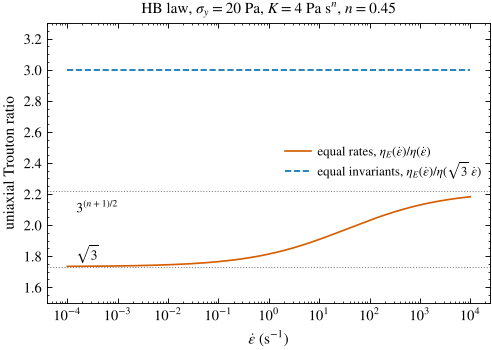

equal-rate ratio: 1.734 at low rate -> 2.182 at high rate; equal-invariant ratio: 3 exactly (planar: 4)


In [7]:
eps = np.logspace(-4, 4, 300)
eta_E = sigma_E_eq11(eps, sy, K, n) / eps
Tr_rate = eta_E / (hb_stress(eps, sy, K, n) / eps)
Tr_inv = eta_E / (hb_stress(np.sqrt(3) * eps, sy, K, n) / (np.sqrt(3) * eps))
eta_P = sigma_P_eq12(eps, sy, K, n) / eps
TrP_inv = eta_P / (hb_stress(2 * eps, sy, K, n) / (2 * eps))
assert np.allclose(Tr_inv, 3.0) and np.allclose(TrP_inv, 4.0)
Tr_rate_at = lambda e: (sigma_E_eq11(e, sy, K, n) / e) / (hb_stress(e, sy, K, n) / e)
assert abs(Tr_rate_at(1e-9) - np.sqrt(3)) < 1e-3 and abs(Tr_rate_at(1e12) - 3 ** ((n + 1) / 2)) < 1e-3   # the two asymptotes

fig, ax = plt.subplots(figsize=(5.2, 3.3))
ax.semilogx(eps, Tr_rate, color=C["red"], label=r"equal rates, $\eta_E(\dot\epsilon)/\eta(\dot\epsilon)$")
ax.semilogx(eps, Tr_inv, color=C["blue"], ls="--", label=r"equal invariants, $\eta_E(\dot\epsilon)/\eta(\sqrt{3}\,\dot\epsilon)$")
ax.axhline(np.sqrt(3), color=C["grey"], lw=0.7, ls=":"); ax.axhline(3 ** ((n + 1) / 2), color=C["grey"], lw=0.7, ls=":")
ax.text(1.5e-4, np.sqrt(3) + 0.04, r"$\sqrt{3}$", fontsize=9); ax.text(1.5e-4, 3 ** ((n + 1) / 2) - 0.14, r"$3^{(n+1)/2}$", fontsize=9)
ax.set(xlabel=r"$\dot\epsilon$ (s$^{-1}$)", ylabel="uniaxial Trouton ratio", ylim=(1.5, 3.3),
       title=rf"HB law, $\sigma_y={sy:g}$ Pa, $K={K:g}$ Pa s$^n$, $n={n}$")
ax.legend(fontsize=8.5, loc="center right")
plt.show()
print(f"equal-rate ratio: {Tr_rate[0]:.3f} at low rate -> {Tr_rate[-1]:.3f} at high rate; equal-invariant ratio: 3 exactly (planar: 4)")

## 5. Von Mises versus Tresca over the Lode angle

### 5.1 The closed form against a direct principal-stress calculation

For each Lode angle we build the principal deviatoric stresses with $\sqrt{J_2}=1$, compute the Tresca measure directly from them, scale to the Tresca surface and compare $\sqrt{J_2}$ at yield with the closed form $1/\sin(\theta+\pi/3)$ of Sec. 1.2 (and with the von Mises value, 1). Notebook 02 drew the same curve; here we also mark the three flows of Sec. 4 with their Lode angles computed from the stress tensors.

In [8]:
theta = np.linspace(0, np.pi / 3, 601)
k = np.arange(3)[:, None]
s_unit = (2 / np.sqrt(3)) * np.cos(theta - 2 * np.pi * k / 3)          # principal deviatoric stresses, sqrt(J2) = 1
J2u, J3u = 0.5 * np.sum(s_unit ** 2, axis=0), np.prod(s_unit, axis=0)
assert np.allclose(J2u, 1.0) and np.allclose(1.5 * np.sqrt(3) * J3u / J2u ** 1.5, np.cos(3 * theta))
ratio_num = 2.0 / (s_unit.max(0) - s_unit.min(0))                        # sqrt(J2) on the Tresca surface / sigma_y
ratio_closed = 1.0 / np.sin(theta + np.pi / 3)
assert np.allclose(ratio_num, ratio_closed)
print(f"Tresca/von Mises strength: {ratio_num.min():.4f} at theta = 30 deg, {ratio_num.max():.4f} at 0 and 60 deg "
      f"(2/sqrt(3) = {2 / np.sqrt(3):.4f}); closed form 1/sin(theta + 60 deg) verified")

flows = {"uniaxial extension": hb_tau(D_uniaxial(1.0), sy, K, n), "simple shear": tau_s,
         "planar extension": hb_tau(D_planar(1.0), sy, K, n),
         "uniaxial compression": hb_tau(D_uniaxial(-1.0), sy, K, n)}     # eps < 0: compression, Lode angle 60 deg
lode = {name: invariants(t)[4] for name, t in flows.items()}
print({k_: round(float(v), 2) for k_, v in lode.items()})

Tresca/von Mises strength: 1.0000 at theta = 30 deg, 1.1547 at 0 and 60 deg (2/sqrt(3) = 1.1547); closed form 1/sin(theta + 60 deg) verified
{'uniaxial extension': 0.0, 'simple shear': 30.0, 'planar extension': 30.0, 'uniaxial compression': 60.0}


### 5.2 The two yield surfaces in the deviatoric plane

In the deviatoric ($\pi$) plane a stress state is a point at distance $\sqrt{2J_2}$ from the origin and polar angle equal to the Lode angle (measured from the uniaxial-tension direction, and repeated with reflections every $60^\circ$). Von Mises is the circle of radius $\sqrt2\,\sigma_y$; Tresca calibrated in simple shear is the circumscribed hexagon. The right panel marks where the four flows of Sec. 5.1 reach the von Mises surface.

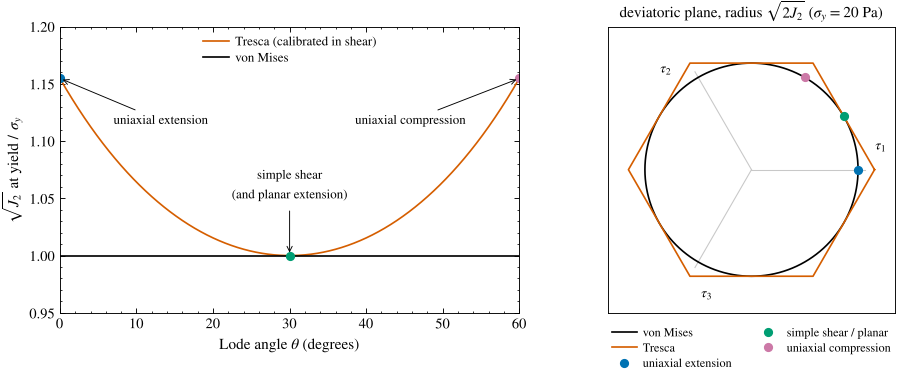

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.7))
ax1.plot(np.degrees(theta), ratio_closed, color=C["red"], label="Tresca (calibrated in shear)")
ax1.axhline(1.0, color=C["black"], label="von Mises")
for name, col, xy_text, ha in [("uniaxial extension", C["blue"], (7, 1.115), "left"),
                               ("simple shear", C["green"], (30, 1.05), "center"),
                               ("uniaxial compression", C["purple"], (53, 1.115), "right")]:
    th = float(lode[name])
    ax1.plot(th, 1 / np.sin(np.radians(th) + np.pi / 3), "o", color=col, ms=5)
    ax1.annotate(name + ("\n(and planar extension)" if name == "simple shear" else ""),
                 (th, 1 / np.sin(np.radians(th) + np.pi / 3)), xy_text, ha=ha, fontsize=8.5,
                 arrowprops=dict(arrowstyle="->", lw=0.6))
ax1.set(xlabel=r"Lode angle $\theta$ (degrees)", ylabel=r"$\sqrt{J_2}$ at yield $/\ \sigma_y$", xlim=(0, 60), ylim=(0.95, 1.2))
ax1.legend(loc="upper center", fontsize=8.5)

phi = np.linspace(0, 2 * np.pi, 1441)
th_fold = np.pi / 3 - np.abs(np.mod(phi, 2 * np.pi / 3) - np.pi / 3)          # fold the polar angle into [0, 60 deg]
r_vm = np.sqrt(2) * sy * np.ones_like(phi)
r_tr = np.sqrt(2) * sy / np.sin(th_fold + np.pi / 3)
ax2.plot(r_vm * np.cos(phi), r_vm * np.sin(phi), color=C["black"], label="von Mises")
ax2.plot(r_tr * np.cos(phi), r_tr * np.sin(phi), color=C["red"], label="Tresca")
for name, col, ang in [("uniaxial extension", C["blue"], 0.0), ("simple shear / planar", C["green"], np.pi / 6),
                       ("uniaxial compression", C["purple"], np.pi / 3)]:
    ax2.plot(np.sqrt(2) * sy * np.cos(ang), np.sqrt(2) * sy * np.sin(ang), "o", color=col, ms=5, label=name)
for ang, lab in [(0, r"$\tau_1$"), (2 * np.pi / 3, r"$\tau_2$"), (4 * np.pi / 3, r"$\tau_3$")]:
    ax2.plot([0, 1.5 * sy * np.cos(ang)], [0, 1.5 * sy * np.sin(ang)], color=C["lightgrey"], lw=0.7, zorder=0)
    ax2.text(1.75 * sy * np.cos(ang + 0.18), 1.75 * sy * np.sin(ang + 0.18), lab, ha="center", va="center", fontsize=9)
ax2.set_aspect("equal"); ax2.set(xlim=(-1.9 * sy, 1.9 * sy), ylim=(-1.9 * sy, 1.9 * sy), xticks=[], yticks=[],
                                 title=rf"deviatoric plane, radius $\sqrt{{2J_2}}$ ($\sigma_y={sy:g}$ Pa)")
ax2.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2)
fig.tight_layout(); plt.show()

### 5.3 Predicted extensional yield stresses

At onset the viscous terms of Eqs. (11)–(12) vanish. Von Mises gives $\sigma_{E,y}=\sqrt3\,\sigma_y$ (uniaxial) and $\sigma_{P,y}=2\sigma_y$ (planar). For Tresca we find the stress state of the same form, $\boldsymbol\tau=\mathrm{diag}(-a,-a,2a)$ or $\mathrm{diag}(a,-a,0)$, at which $\max\tau_i-\min\tau_i=2\sigma_y$.

In [10]:
def yield_ratio(D_dir, criterion, sy=1.0):
    '''Tensile yield stress / shear yield stress for a stress state proportional to D_dir, under either criterion.'''
    T = D_dir / magnitude(D_dir)                       # unit-magnitude stress state with the direction of D
    if criterion == "von Mises":
        scale = sy                                     # sqrt(J2) = sigma_y
    else:
        scale = 2 * sy / tresca_measure(T)             # max - min = 2 sigma_y
    T = scale * T
    p = np.sort(np.linalg.eigvalsh(T))
    return (p[-1] - p[0]) / sy                         # net tensile stress (largest minus smallest principal stress)

table = pd.DataFrame({crit: {flow: yield_ratio(Dd, crit) for flow, Dd in
                             [("uniaxial, sigma_E,y / sigma_y", D_uniaxial(1.0)), ("planar, sigma_P,y / sigma_y", D_planar(1.0))]}
                      for crit in ["von Mises", "Tresca"]})
print(table.round(4).to_string())
assert np.allclose(table.loc["uniaxial, sigma_E,y / sigma_y"], [np.sqrt(3), 2.0])
assert np.allclose(table.loc["planar, sigma_P,y / sigma_y"], [2.0, 2.0])
print(f"\nuniaxial: Tresca/von Mises = {2 / np.sqrt(3):.4f} (+{100 * (2 / np.sqrt(3) - 1):.1f} %); planar: identical (J3 = 0)")

                               von Mises  Tresca
uniaxial, sigma_E,y / sigma_y     1.7321     2.0
planar, sigma_P,y / sigma_y       2.0000     2.0

uniaxial: Tresca/von Mises = 1.1547 (+15.5 %); planar: identical (J3 = 0)


## 6. Confronting the prediction with measured yield ratios

### 6.1 The gravity-filament numbers (Sec. IV B)

Geffrault et al. (2021) measured the extensional yield stress of a kaolin suspension and of a concentrated emulsion by extensional gravity rheometry. We redo the arithmetic of Sec. IV B with the shear yield stresses of the parameter atlas (`data/hb_parameter_atlas.csv`, Fig. 3).

In [11]:
atlas = pd.read_csv(DATA / "hb_parameter_atlas.csv")
geff = atlas[atlas.source_key == "Geffrault2021"].set_index("material")
print(geff[["sigma_y_Pa", "K_Pa_s_n", "n", "source_location"]].to_string(), "\n")

measured = {"Kaolin suspension 27 vol%": [("", 517.0)],
            "Dodecane-in-water emulsion 88 vol%": [("2 cm nozzle", 98.0), ("1 cm nozzle", 84.0)]}   # Pa, Sec. IV B
rows = []
for mat, obs in measured.items():
    sy_m = float(geff.loc[mat, "sigma_y_Pa"])
    vm, tr = np.sqrt(3) * sy_m, 2 * sy_m
    for tag, m in obs:
        rows.append({"material": mat + (f" ({tag})" if tag else ""), "shear sigma_y (Pa)": sy_m, "von Mises (Pa)": vm,
                     "Tresca (Pa)": tr, "measured (Pa)": m, "ratio": m / sy_m,
                     "vs von Mises (%)": 100 * (m / vm - 1), "vs Tresca (%)": 100 * (m / tr - 1)})
geff_tab = pd.DataFrame(rows).set_index("material")
print(geff_tab.round(2).to_string())
# the numbers printed in Sec. IV B: 535 and 618 Pa for kaolin, 90 and 104 Pa for the emulsion; -16 % vs Tresca for kaolin
assert np.allclose(geff_tab["von Mises (Pa)"].round(0).unique(), [535, 90]) and np.allclose(geff_tab["Tresca (Pa)"].round(0).unique(), [618, 104])
assert round(geff_tab.loc["Kaolin suspension 27 vol%", "vs Tresca (%)"]) == -16 and round(geff_tab.loc["Kaolin suspension 27 vol%", "vs von Mises (%)"]) == -3
assert round(geff_tab.loc["Dodecane-in-water emulsion 88 vol% (2 cm nozzle)", "vs von Mises (%)"]) == 9
print("\nSec. IV B / IX C numbers reproduced: kaolin -3 % (von Mises) and -16 % (Tresca); emulsion +9 % (2 cm) and bracketing von Mises.")

                                    sigma_y_Pa  K_Pa_s_n      n                                       source_location
material                                                                                                             
Dodecane-in-water emulsion 88 vol%        52.0     10.75  0.333  materials section (shear-rheometry characterization)
Kaolin suspension 27 vol%                309.0     78.00  0.333  materials section (shear-rheometry characterization) 

                                                  shear sigma_y (Pa)  von Mises (Pa)  Tresca (Pa)  measured (Pa)  ratio  vs von Mises (%)  vs Tresca (%)
material                                                                                                                                                
Kaolin suspension 27 vol%                                      309.0          535.20        618.0          517.0   1.67             -3.40         -16.34
Dodecane-in-water emulsion 88 vol% (2 cm nozzle)                52.

For the kaolin, $-16$ % against a stated uncertainty of about 12 % disfavors Tresca; the emulsion values with the two nozzles bracket the von Mises prediction, the difference being attributed to capillarity. Sec. IX C adds that the finite-rate exponents refitted in extension were 0.4 (kaolin) and 0.67 (emulsion) against $1/3$ in shear, so that the shear-calibrated Eq. (11) underestimates the tensile stress above a few s$^{-1}$. The next cell draws Eq. (11) for both materials with their shear parameters, i.e. the prediction that the onset agrees with and the flow curve departs from.

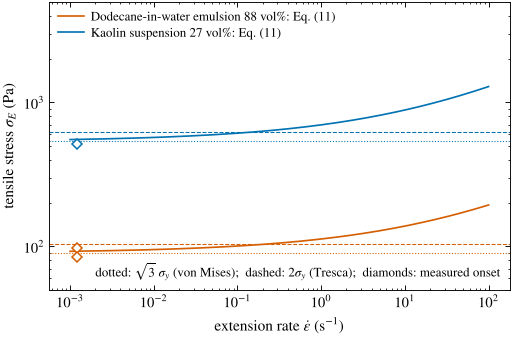

In [12]:
eps = np.logspace(-3, 2, 200)
fig, ax = plt.subplots(figsize=(5.4, 3.4))
for (mat, r), col in zip(geff.iterrows(), [C["red"], C["blue"]]):
    sE = sigma_E_eq11(eps, r.sigma_y_Pa, r.K_Pa_s_n, r.n)
    ax.loglog(eps, sE, color=col, label=f"{mat.split(' (')[0]}: Eq. (11)")
    ax.axhline(np.sqrt(3) * r.sigma_y_Pa, color=col, lw=0.7, ls=":")
    ax.axhline(2 * r.sigma_y_Pa, color=col, lw=0.7, ls="--")
    for tag, m in measured[mat]:
        ax.plot(1.2e-3, m, "D", color=col, mfc="white", ms=5)
ax.text(0.98, 0.03, r"dotted: $\sqrt{3}\,\sigma_y$ (von Mises);  dashed: $2\sigma_y$ (Tresca);  diamonds: measured onset",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8.5)
ax.set(xlabel=r"extension rate $\dot\epsilon$ (s$^{-1}$)", ylabel=r"tensile stress $\sigma_E$ (Pa)", ylim=(50, 5000))
ax.legend(fontsize=8.5, loc="upper left"); plt.show()

### 6.2 All reported ratios against the two criteria (Sec. IX C)

Sec. IX C collects the extensional-to-shear yield-stress ratios measured with different protocols. We transcribe them below (the two Zhang et al. values are printed as multiples of $\sqrt3$; the 1-cm-nozzle ratio of the emulsion is computed from the stresses printed in Sec. IV B) and plot them against the predictions of Sec. 5.3: $\sqrt3$ (von Mises) and 2 (Tresca) for uniaxial tests, 2 for both in planar extension.

In [13]:
ratios = pd.DataFrame([
    # protocol, study, material, ratio, low, high, flow type
    ("capillary thinning", "Martinie et al. 2013", "17 soft materials (mean; range)", 1.91, 1.26, 2.44, "uniaxial"),
    ("plate separation",   "Zhang et al. 2018",    "emulsions and Carbopol gels",   1.5 * np.sqrt(3), None, None, "uniaxial"),
    ("plate separation",   "Zhang et al. 2018",    "mustard and ketchup",           2.5 * np.sqrt(3), None, None, "uniaxial"),
    ("gravity filament",   "Geffrault et al. 2021", "kaolin suspension",            517 / 309, None, None, "uniaxial"),
    ("gravity filament",   "Geffrault et al. 2021", "emulsion, 2 cm nozzle",        98 / 52, None, None, "uniaxial"),
    ("gravity filament",   "Geffrault et al. 2021", "emulsion, 1 cm nozzle",        84 / 52, None, None, "uniaxial"),
    ("cross-slot (planar)", "Varchanis et al. 2020", "Pluronic gel (Saramito HB model)", 2.04, None, None, "planar"),
], columns=["protocol", "study", "material", "ratio", "low", "high", "flow"])
ratios["vs von Mises (%)"] = 100 * (ratios.ratio / np.where(ratios.flow == "uniaxial", np.sqrt(3), 2.0) - 1)
ratios["vs Tresca (%)"] = 100 * (ratios.ratio / 2.0 - 1)
print(ratios.drop(columns=["low", "high"]).round(2).to_string(index=False))

# the summary statements of Secs. IV B and IX C
uni = ratios[ratios.flow == "uniaxial"]
assert round(uni.ratio.iloc[0], 2) == 1.91 and (uni.low.iloc[0], uni.high.iloc[0]) == (1.26, 2.44)      # Martinie: mean 1.91, range 1.26-2.44
assert np.isclose(uni.ratio.iloc[1], 2.5981) and round(uni.ratio.iloc[2], 1) == 4.3                    # Zhang: 1.5 sqrt3 = 2.6, 2.5 sqrt3 = 4.3
assert round(uni.ratio.iloc[3], 2) == 1.67 and round(uni.ratio.iloc[4], 2) == 1.88                       # Geffrault: 1.67, 1.88
grav = uni.ratio.iloc[3:5]            # the two gravity-filament ratios printed in Sec. IX C (kaolin; emulsion, 2 cm nozzle)
print(f"\nmean ratios by protocol: capillary thinning {uni.ratio.iloc[0]:.2f}, plate separation {uni.ratio.iloc[1]:.1f} "
      f"(emulsions, gels) and {uni.ratio.iloc[2]:.1f} (mustard, ketchup), gravity filaments {grav.min():.2f}-{grav.max():.2f}"
      f" (1 cm nozzle: {uni.ratio.iloc[5]:.2f})")
print(f"individual emulsions and gels: {uni.low.iloc[0]:.2f} to {uni.ratio.iloc[1]:.1f}; across protocols the means span "
      f"{min(uni.ratio.iloc[0], grav.min()):.1f} to {uni.ratio.iloc[1]:.1f} (Sec. IX C: 1.7 to 2.6)")
assert round(min(grav), 1) == 1.7 and round(max(grav), 1) == 1.9 and round(uni.ratio.iloc[1], 1) == 2.6

           protocol                 study                         material  ratio     flow  vs von Mises (%)  vs Tresca (%)
 capillary thinning  Martinie et al. 2013  17 soft materials (mean; range)   1.91 uniaxial             10.27          -4.50
   plate separation     Zhang et al. 2018      emulsions and Carbopol gels   2.60 uniaxial             50.00          29.90
   plate separation     Zhang et al. 2018              mustard and ketchup   4.33 uniaxial            150.00         116.51
   gravity filament Geffrault et al. 2021                kaolin suspension   1.67 uniaxial             -3.40         -16.34
   gravity filament Geffrault et al. 2021            emulsion, 2 cm nozzle   1.88 uniaxial              8.81          -5.77
   gravity filament Geffrault et al. 2021            emulsion, 1 cm nozzle   1.62 uniaxial             -6.74         -19.23
cross-slot (planar) Varchanis et al. 2020 Pluronic gel (Saramito HB model)   2.04   planar              2.00           2.00

mean ra

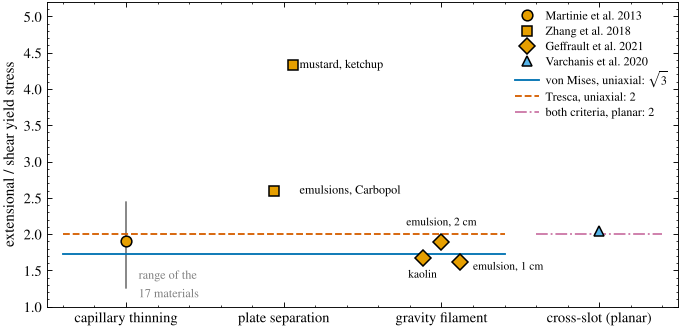

In [14]:
fig, ax = plt.subplots(figsize=(7.4, 3.6))
protocols = list(dict.fromkeys(ratios.protocol))
xpos = {p: i for i, p in enumerate(protocols)}
mk = {"Martinie et al. 2013": "o", "Zhang et al. 2018": "s", "Geffrault et al. 2021": "D", "Varchanis et al. 2020": "^"}
for i, r in ratios.iterrows():
    x = xpos[r.protocol] + 0.12 * (i - np.mean(ratios.index[ratios.protocol == r.protocol]))   # spread points within a protocol
    if r.low is not None and not pd.isna(r.low):
        ax.plot([x, x], [r.low, r.high], color=C["grey"], lw=1.2, solid_capstyle="round", zorder=1)
    ax.plot(x, r.ratio, mk[r.study], color=C["black"], mfc=C["orange"] if r.flow == "uniaxial" else C["cyan"], ms=7, zorder=3,
            label=r.study if r.study not in ax.get_legend_handles_labels()[1] else None)
# predictions: uniaxial tests (three protocols) and the planar test
ax.plot([-0.4, 2.4], [np.sqrt(3)] * 2, color=C["blue"], lw=1.2, label=r"von Mises, uniaxial: $\sqrt{3}$")
ax.plot([-0.4, 2.4], [2.0] * 2, color=C["red"], lw=1.2, ls="--", label="Tresca, uniaxial: 2")
ax.plot([2.6, 3.4], [2.0] * 2, color=C["purple"], lw=1.2, ls="-.", label="both criteria, planar: 2")
ax.text(0.08, 1.3, "range of the\n17 materials", ha="left", va="center", fontsize=8, color=C["grey"])
ax.text(1.1, 4.33, "mustard, ketchup", ha="left", va="center", fontsize=8)
ax.text(1.1, 2.6, "emulsions, Carbopol", ha="left", va="center", fontsize=8)
xg = xpos["gravity filament"]
for xy, lab, ha in [((xg - 0.12, 1.44), "kaolin", "center"), ((xg, 2.16), "emulsion, 2 cm", "center"),
                    ((xg + 0.2, 1.55), "emulsion, 1 cm", "left")]:
    ax.text(*xy, lab, ha=ha, va="center", fontsize=7.5)
ax.set_xticks(range(len(protocols))); ax.set_xticklabels(protocols)
ax.set(ylabel=r"extensional / shear yield stress", xlim=(-0.5, 3.5), ylim=(1.0, 5.2))
ax.legend(fontsize=8, loc="upper right")
plt.show()

Of the six uniaxial points, two lie between the predictions (capillary-thinning mean 1.91; emulsion with the 2 cm nozzle, 1.88), two lie above both (plate separation, 2.6 and 4.3) and two lie below $\sqrt3$ (kaolin, 1.67; emulsion with the 1 cm nozzle, 1.62). The review draws the conclusion carefully (Sec. IX C): the spread exceeds the stated uncertainties and *correlates with the protocol* — filament thinning, plate separation or gravity drainage — which points to differences in deformation history and wall conditions rather than to one universal yield function. The onset was predicted with shear parameters in gravity-driven filaments and, for 11 of the 17 materials of Martinie et al., in capillary thinning (Sec. IX H; Table XII, group D); the plate-separation ratios were not captured; and the planar ratio 2.04 against 2 of Varchanis et al. (2020) was obtained with an elastoviscoplastic (Saramito HB) model whose modulus was measured independently in oscillation. Failure in extension lies further still from the baseline: the tensorial law never allows stable uniaxial extension (zero critical strain), whereas Nelson et al. (2018) measured strains to break far beyond it (Sec. IV E). Note also that a planar test cannot distinguish the criteria at all (Sec. 5.3), and that filament tests couple the constitutive response to capillary pressure, drainage, necking and end conditions, so a tensile force divided by an apparent area is not the homogeneous stress of Eq. (11) (Sec. IV E).

## 7. Normal stresses and the yield invariant (Note S3)

Real yield-stress fluids carry normal-stress differences in simple shear ($N_1>0$, $N_2<0$, both $\propto\sigma^2$; de Cagny et al., 2019), which the isotropic law cannot produce (Sec. 4.1). Do they move the onset invariant? We build the full stress tensor of a shear state with $N_1=\psi_1\sigma^2$ and $N_2=\psi_2\sigma^2$, evaluate $\sqrt{J_2}$ with the generic `invariants` function, and compare with Eq. (S5). Notebook 10 reproduces Fig. S2 in full; here we only reproduce the numbers of Note S3 and check them against the stored reconstruction and the figure data.

In [15]:
recon = json.loads((DATA / "normal_stress_reconstruction.json").read_text())
mat = pd.DataFrame(recon["materials"]).set_index("material")
fdS2 = pd.read_csv(FIGDATA / "figS2_normal_stress.csv", comment="#")

def shear_state(s, N1, N2):
    '''Stress tensor of simple shear tau_xy = s with normal-stress differences N1 = txx - tyy, N2 = tyy - tzz.'''
    T = np.diag([N1 + N2, N2, 0.0]); T[0, 1] = T[1, 0] = s
    return T

def sigma_d_eq_S5(s, N1, N2):
    return np.sqrt(s ** 2 + (N1 ** 2 + N1 * N2 + N2 ** 2) / 3)

rows = []
for name, m in mat.iterrows():
    p1, p2, sy_m = m.psi1_Pa_inv, m.psi2_Pa_inv, m.sigma_y_Pa
    out = {"material": name, "sigma_y (Pa)": sy_m}
    for s_, tag in [(sy_m, "at sigma_y"), (100.0, "at 100 Pa"), (300.0, "at 300 Pa")]:
        N1, N2 = p1 * s_ ** 2, p2 * s_ ** 2
        _, J2, J3, sJ2, theta = invariants(shear_state(s_, N1, N2))
        assert np.isclose(sJ2, sigma_d_eq_S5(s_, N1, N2))                 # generic invariant = Eq. (S5)
        out[f"increase {tag} (%)"] = 100 * (sJ2 / s_ - 1)
        if tag == "at sigma_y":
            out["N1 at sigma_y (Pa)"] = N1; out["N1/sigma"] = N1 / sy_m; out["Lode angle at sigma_y (deg)"] = theta
    # stored reconstruction (scripts/figS2_normal_stress.py) and the plotted curve of Fig. S2(b)
    assert np.isclose(out["increase at sigma_y (%)"], m.equivalent_stress_increment_at_intercept_percent)
    curve = fdS2[(fdS2.panel == "(b)") & (fdS2.series == name)].sort_values("index")
    assert np.isclose(curve.x.iloc[-1], 300.0) and np.isclose(curve.y.iloc[-1], out["increase at 300 Pa (%)"], rtol=1e-8)
    marker = fdS2[(fdS2.panel == "(b)") & (fdS2.series == f"{name}: value at sigma = sigma_y")]
    assert np.isclose(marker.y.iloc[0], out["increase at sigma_y (%)"], rtol=1e-8)
    rows.append(out)
noteS3 = pd.DataFrame(rows).set_index("material")
print(noteS3.round(3).to_string())
inc = noteS3["increase at sigma_y (%)"].round(2).tolist()
assert inc == [0.39, 0.41, 0.56] and noteS3["increase at 300 Pa (%)"].between(11, 12.5).all()
print("\nNote S3 reproduced: increments 0.39, 0.41 and 0.56 % at the shear yield stress, about 1.3 % at 100 Pa and 11-12 % at 300 Pa;"
      "\nvalues agree with data/normal_stress_reconstruction.json and with Fig. S2(b) in data/figure_data/figS2_normal_stress.csv.")

          sigma_y (Pa)  increase at sigma_y (%)  N1 at sigma_y (Pa)  N1/sigma  Lode angle at sigma_y (deg)  increase at 100 Pa (%)  increase at 300 Pa (%)
material                                                                                                                                                  
Emulsion         53.56                    0.389               9.151     0.171                       31.280                   1.350                  11.568
Hair gel         56.50                    0.413              10.279     0.182                       29.926                   1.288                  11.056
Carbopol         65.51                    0.562              12.832     0.196                       32.339                   1.305                  11.197

Note S3 reproduced: increments 0.39, 0.41 and 0.56 % at the shear yield stress, about 1.3 % at 100 Pa and 11-12 % at 300 Pa;
values agree with data/normal_stress_reconstruction.json and with Fig. S2(b) in data/figure_data/fi

At yield, $N_1$ is about a fifth of the shear stress, yet $\sigma_d$ exceeds $\sigma$ by only 0.4–0.6 % — the squares in Eq. (S5) — so the onset invariant is practically unchanged, as de Cagny et al. concluded. Because $N_i\propto\sigma^2$ the increment reaches 11–12 % at 300 Pa, where normal stresses dominate a normal-force reading without affecting the onset.

**A side remark (beyond the article).** The table also lists the Lode angle of the shear state with normal stresses: it is no longer exactly $30^\circ$, because the normal stresses make $J_3\neq0$. A Tresca criterion would therefore read the same stress state slightly differently from von Mises. The next cell quantifies the difference at the shear yield stress: it is below $10^{-3}$ relative, far too small to matter.

In [16]:
for name, m in mat.iterrows():
    sy_m = m.sigma_y_Pa
    T = shear_state(sy_m, m.psi1_Pa_inv * sy_m ** 2, m.psi2_Pa_inv * sy_m ** 2)
    vm = invariants(T)[3] / sy_m                       # sqrt(J2) / sigma_y
    tr = tresca_measure(T) / (2 * sy_m)                # (max - min) / (2 sigma_y)
    print(f"{name:9s}: von Mises invariant / sigma_y = {vm:.5f}, Tresca measure / (2 sigma_y) = {tr:.5f}, "
          f"difference {100 * (tr / vm - 1):+.3f} %")
    assert abs(tr / vm - 1) < 1e-3

Emulsion : von Mises invariant / sigma_y = 1.00389, Tresca measure / (2 sigma_y) = 1.00364, difference -0.025 %
Hair gel : von Mises invariant / sigma_y = 1.00413, Tresca measure / (2 sigma_y) = 1.00413, difference -0.000 %
Carbopol : von Mises invariant / sigma_y = 1.00562, Tresca measure / (2 sigma_y) = 1.00478, difference -0.083 %


## 8. Try it yourself

**Exercise 1 — equibiaxial extension.** A sheet stretched equally in two directions has $\mathbf D=\mathrm{diag}(\dot\epsilon,\dot\epsilon,-2\dot\epsilon)$. Show with `hb_tau` and `invariants` that the Lode angle is $60^\circ$ ($J_3<0$), that the net stress $\tau_{xx}-\tau_{zz}$ at onset is again $\sqrt3\,\sigma_y$ under von Mises, and that Tresca predicts $2\sigma_y$. Why is this flow no better than uniaxial extension at separating the criteria, and no worse?

*Hint:* equibiaxial extension at rate $\dot\epsilon$ is uniaxial compression along $z$ at rate $2\dot\epsilon$, `D_uniaxial(-2*eps)`; compare with `lode["uniaxial compression"]`.

<details><summary>Solution</summary>

```python
D_b = np.diag([1.0, 1.0, -2.0])
t_b = hb_tau(D_b, sy, K, n)
print(invariants(t_b)[4], invariants(t_b)[2] < 0)                       # 60 deg, J3 < 0
print(yield_ratio(D_b, "von Mises"), yield_ratio(D_b, "Tresca"))        # 1.732, 2.0
```
The Lode angle is $60^\circ$ and $J_3<0$; the yield ratios are $\sqrt3\approx1.732$ (von Mises) and 2 (Tresca), the same pair as in uniaxial extension because the Tresca hexagon has the same distance from the circle at $0^\circ$ and $60^\circ$ (Sec. 5.1). The two criteria again differ by 15 %, so the test is exactly as discriminating as uniaxial extension — and needs the same precision.
</details>

**Exercise 2 — how precise must the yield stresses be?** Suppose the shear and extensional yield stresses are each measured with the same relative standard uncertainty $u$, independently. The ratio then has relative uncertainty $\approx\sqrt2\,u$. At what $u$ do the von Mises and Tresca predictions, $\sqrt3$ and 2, differ by two standard uncertainties of the measured ratio? Compare with the kaolin measurement (uncertainty about 12 %).

*Hint:* the two predictions differ by $2/\sqrt3-1\approx15.5$ % of the von Mises value.

<details><summary>Solution</summary>

```python
gap = 2 / np.sqrt(3) - 1
u = gap / (2 * np.sqrt(2))
print(f"u = {100 * u:.1f} %")
```
The criteria are two standard uncertainties apart when $u\approx5.5$ %; with about 12 % on the kaolin ratio alone the separation is only about one standard uncertainty, which is why the review says the result "disfavors" rather than "rejects" Tresca and that separating the criteria requires uncertainties "well below" 15 % on both yield stresses.
</details>

**Exercise 3 — a mixed flow.** Superpose simple shear and uniaxial extension, $\mathbf D=\mathbf D_{\rm shear}(\dot\gamma)+\mathbf D_{\rm uni}(\dot\epsilon)$, and plot the Lode angle of the HB stress against the mixing fraction $f=\dot\epsilon/(\dot\gamma+\dot\epsilon)$ from 0 to 1. For which $f$ is $J_3=0$? Why does the superposed rotation-plus-squeeze experiment of Ovarlez, Barral and Coussot (2010) nevertheless have $J_3=0$ exactly?

*Hint:* the Lode angle of the HB stress equals that of $\mathbf D$ (associated flow rule), so you may apply `invariants` to $\mathbf D$ itself. A squeeze flow between plates is locally a shear, not an extension.

<details><summary>Solution</summary>

```python
f = np.linspace(0, 1, 201)
th = []
for fi in f:
    Lm = np.zeros((3, 3)); Lm[0, 1] = 1 - fi
    Dm = D_from_grad(Lm) + D_uniaxial(fi)
    th.append(invariants(Dm)[4])
plt.plot(f, th); plt.xlabel("f"); plt.ylabel("Lode angle (deg)"); plt.show()
```
The curve is not monotonic: the Lode angle starts at $30^\circ$ ($f=0$, simple shear), rises to exactly $60^\circ$ at $f=0.25$, where the principal rates are $(0.25,0.25,-0.5)$, a uniaxial-compression (equibiaxial) state: the extension along $z$ raises the intermediate, zero principal rate of the shear until it equals the largest one, so $J_3<0$. It returns to $30^\circ$ at $f=0.5$, where the principal rates are $(0.5,0,-0.5)$, a pure shear again with $J_3=0$, and then falls to $0$ (uniaxial extension, $J_3>0$) at $f=1$. $J_3$ vanishes at $f=0$ and $f=0.5$. In the rotation-plus-squeeze experiment both superposed flows are shears with $J_3=0$ in every combination, so the test fixes the Lode angle at $30^\circ$ and supports isotropy and normality without probing the $\theta$ dependence (Sec. IX C).
</details>

## Key points

* The tensorial HB law, Eq. (4), makes $\boldsymbol\tau$ parallel to $\mathbf D$ (associated flow rule) and puts the invariant pair $(\sigma,\dot\gamma)$ on the shear flow curve in **every** flow; it is traceless, objective and derives from the convex potential (S2).
* Simple shear and planar extension have $J_3=0$ (Lode angle $30^\circ$); uniaxial extension has $J_3\neq0$ (Lode angle 0). Tresca, calibrated in shear, is stronger than von Mises by $1/\sin(\theta+\pi/3)$, at most $2/\sqrt3\approx1.155$: the criteria predict tensile yield stresses $\sqrt3\,\sigma_y$ and $2\sigma_y$ in uniaxial extension and the same $2\sigma_y$ in planar extension.
* Eqs. (11) and (12), $\sigma_E=\sqrt3\sigma_y+3^{(n+1)/2}K\dot\epsilon^n$ and $\sigma_P=2\sigma_y+2^{n+1}K\dot\epsilon^n$, follow from Eq. (4) with $\dot\gamma=\sqrt3\dot\epsilon$ and $2\dot\epsilon$; they recover the Trouton factors 3 and 4, and the Trouton ratio of a yield-stress fluid depends on whether equal rates or equal invariants are compared (exactly 3 and 4 at equal invariants).
* Measured uniaxial yield ratios range from 1.3 to 2.6 for individual emulsions and gels, with protocol means of 1.7–1.9 (gravity filaments), 1.9 (capillary thinning) and 2.6 (plate separation), and about 4.3 for mustard and ketchup; the kaolin filament result (517 Pa against 535 and 618 Pa) disfavors Tresca, but the spread across protocols points to deformation history and wall conditions rather than to a universal yield function. The planar ratio 2.04 against 2 was obtained with an elastoviscoplastic extension.
* Normal-stress differences of about $\sigma_y/5$ raise the von Mises invariant at yield by only 0.39–0.56 % (Eq. (S5)), but by 11–12 % at 300 Pa: negligible for onset, not for normal-force observables.

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* de Cagny, H., Fazilati, M., Habibi, M., Denn, M. M., and Bonn, D. (2019). The yield normal stress. *Journal of Rheology* **63**, 285–290. https://doi.org/10.1122/1.5063796
* Geffrault, A., Bessaies-Bey, H., Roussel, N., and Coussot, P. (2021). Extensional gravity-rheometry (EGR) for yield stress fluids. *Journal of Rheology* **65**, 887–901. https://doi.org/10.1122/8.0000241
* Herschel, W. H., and Bulkley, R. (1926). Konsistenzmessungen von Gummi-Benzollösungen. *Kolloid-Zeitschrift* **39**, 291–300. https://doi.org/10.1007/bf01432034
* Hohenemser, K., and Prager, W. (1932). Über die Ansätze der Mechanik isotroper Kontinua. *ZAMM – Zeitschrift für Angewandte Mathematik und Mechanik* **12**, 216–226. https://doi.org/10.1002/zamm.19320120403
* Martinie, L., Buggisch, H., and Willenbacher, N. (2013). Apparent elongational yield stress of soft matter. *Journal of Rheology* **57**, 627–646. https://doi.org/10.1122/1.4789785
* Nelson, A. Z., Bras, R. E., Liu, J., and Ewoldt, R. H. (2018). Extending yield-stress fluid paradigms. *Journal of Rheology* **62**, 357–369. https://doi.org/10.1122/1.5003841
* Oldroyd, J. G. (1947). A rational formulation of the equations of plastic flow for a Bingham solid. *Mathematical Proceedings of the Cambridge Philosophical Society* **43**, 100–105. https://doi.org/10.1017/s0305004100023239
* Ovarlez, G., Barral, Q., and Coussot, P. (2010). Three-dimensional jamming and flows of soft glassy materials. *Nature Materials* **9**, 115–119. https://doi.org/10.1038/nmat2615
* Varchanis, S., Haward, S. J., Hopkins, C. C., Syrakos, A., Shen, A. Q., Dimakopoulos, Y., and Tsamopoulos, J. (2020). Transition between solid and liquid state of yield-stress fluids under purely extensional deformations. *Proceedings of the National Academy of Sciences* **117**, 12611–12617. https://doi.org/10.1073/pnas.1922242117
* Zhang, X., Fadoul, O., Lorenceau, E., and Coussot, P. (2018). Yielding and flow of soft-jammed systems in elongation. *Physical Review Letters* **120**, 048001. https://doi.org/10.1103/PhysRevLett.120.048001

### Further reading

* Balmforth, N. J., Frigaard, I. A., and Ovarlez, G. (2014). Yielding to stress: Recent developments in viscoplastic fluid mechanics. *Annual Review of Fluid Mechanics* **46**, 121–146. https://doi.org/10.1146/annurev-fluid-010313-141424
* Coussot, P. (2005). *Rheometry of Pastes, Suspensions and Granular Materials* (Wiley, Hoboken). https://doi.org/10.1002/0471720577
* Saramito, P. (2009). A new elastoviscoplastic model based on the Herschel–Bulkley viscoplastic model. *Journal of Non-Newtonian Fluid Mechanics* **158**, 154–161. https://doi.org/10.1016/j.jnnfm.2008.12.001